In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.animation import FuncAnimation
from IPython import display
from tqdm import tqdm
import numpy as np
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score
from scipy.stats import yulesimon, linregress
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

## Import the data
The data used for the analysis is imported from the `publications_research_year_domain.parquet` file and stored in the `cleaned_papers` dataframe.

In [2]:
DATA1 = Path('../data/processed')

cleaned_papers = pd.read_parquet(DATA1 / 'publications_research_year_domain.parquet')
cleaned_papers = cleaned_papers.drop_duplicates(subset="doi").reset_index(drop=True)

## Analysis of researcher publication distributions across scientific domains

This code processes scientific publications from four research domains (Health Sciences, Physical Sciences, Life Sciences, and Social Sciences) to analyse the distribution of publications per researcher and calculate their complementary cumulative distribution functions (CCDFs).

### 1. Separation by scientific domain
The `cleaned_papers` DataFrame is divided into four subsets according to the `domain_name` column:
- Health Sciences
- Physical Sciences
- Life Sciences
- Social Sciences

### 2. Expansion of researcher lists
The `.explode('orcidResearchers')` operation expands the researcher lists, creating one row per researcher and publication. This allows individual publication counts to be calculated for each researcher within each domain.

### 3. Counting publications per researcher
The `value_counts()` method calculates the number of publications associated with each researcher. The resulting distributions are stored in `grouped`.

### 4. Construction of frequency distributions
For each domain, the code calculates how many researchers have published a given number of papers. The resulting DataFrame (`dif`) contains:
- `value`: Number of publications per researcher.
- `count`: Number of researchers with that publication count.

### 5. Calculation of cumulative distributions
Three cumulative measures are calculated:
- `cdf`: Cumulative distribution function (CDF), representing the fraction of researchers with at most a given number of publications.
- `surv`: Complementary cumulative distribution function (CCDF), calculated as $1-\mathrm{CDF}$, representing the fraction with more than a given number of publications.
- `surv_ge`: Survival probability including the current value, representing the fraction of researchers with at least a given number of publications.

### 6. Normalization
The publication counts are then normalized by dividing them by their mean (`x.mean()`), producing a rescaled horizontal axis (`x_norm`).

### 7. Storage of results
The results are stored in three main lists:
- `grouped`: Number of publications per researcher in each scientific domain.
- `difs`: Original publication-count values and their corresponding survival probabilities.
- `difs_norm`: Normalized publication-count values and their corresponding survival probabilities.


In [3]:
domains = []
domains.append(cleaned_papers[cleaned_papers['domain_name'] == 'Health Sciences']) 
domains.append(cleaned_papers[cleaned_papers['domain_name'] == 'Physical Sciences'])
domains.append(cleaned_papers[cleaned_papers['domain_name'] == 'Life Sciences']) 
domains.append(cleaned_papers[cleaned_papers['domain_name'] == 'Social Sciences']) 

exploded_domains = []
for i in range(0,4):
    exploded_domains.append(domains[i].explode('orcidResearchers'))
grouped = []
difs = []
difs_norm = []
for i in range(0,4):
    grouped.append(exploded_domains[i]['orcidResearchers'].value_counts())
    vc = grouped[i].value_counts().sort_index()            # counts per value, ascending x

    dif = pd.DataFrame({
        "value": vc.index,
        "count": vc.values,
    })
    dif["cdf"]   = dif["count"].cumsum() / dif["count"].sum()
    dif["surv"]  = 1 - dif["cdf"]                 # this is what you plot
    # optional: "fraction >= x" instead of "> x"
    dif["surv_ge"] = dif["surv"] + dif["count"] / dif["count"].sum()
    
    x = dif["value"].to_numpy(dtype=float)
    y = dif["surv_ge"].to_numpy(dtype=float)
    # Area under the curve
    #area = np.trapezoid(y, x)

    # Normalize so area = 1
    #if area > 0:
    x_norm = x / (x.mean())
    #else:
    #    x_norm = x
    difs.append([dif['value'],dif["surv_ge"]])
    difs_norm.append([x_norm,y])
    print(x.mean())
print('ja està!')

164.43795620437956
205.06462585034015
106.47953216374269
73.56140350877193
ja està!


## Repeating the previous process for data not separated by domains

In [4]:

exploded_papers_all = cleaned_papers.explode('orcidResearchers')
grouped_all = exploded_papers_all['orcidResearchers'].value_counts() 
vc = grouped_all.value_counts().sort_index()            # counts per value, ascending x

dif_all = pd.DataFrame({
    "value": vc.index,
    "count": vc.values,
})
dif_all["cdf"]   = dif_all["count"].cumsum() / dif_all["count"].sum()
dif_all["surv"]  = 1 - dif_all["cdf"]                 # this is what you plot
# optional: "fraction >= x" instead of "> x"
dif_all["surv_ge"] = dif_all["surv"] + dif_all["count"] / dif_all["count"].sum()

x = dif_all["value"].to_numpy(dtype=float)
y = dif_all["surv_ge"].to_numpy(dtype=float)
# Area under the curve
area = np.trapezoid(y, x)

# Normalize so area = 1
if area > 0:
    x_norm = x / (x.mean())
else:
    x_norm = x
dif_norm_all = [x_norm,y]

## Yule Simon estimation

In [5]:
def f(data, rho):
    N = len(data)
    double_sum = 0
    for k in data:
        for j in range(1, k+1):
            double_sum = double_sum + 1 / (rho + j)
    return N / double_sum 

In [6]:
mle_rhos = []
yulest = []
for i in range(0,4):
    rho_0 = 0 # initial guess
    epsilon = 0.00000001 # tolerance

    converged = False
    while not converged:
        rho_1 = f(grouped[i], rho_0)
        converged = abs(rho_1 - rho_0) < epsilon
        rho_0 = rho_1
        print(rho_1)
    print('--------------------------')    
    mle_rho = rho_1
    mle_rhos.append(mle_rho)
    vc = grouped[i].value_counts().sort_index()
    est_probs = yulesimon.pmf(vc.index, mle_rho) # Probabilities
    yulest.append(est_probs)
#print(yulest[0])
mle_rhos

0.39590115792507974
0.47438077927730893
0.4884996603677579
0.49099956892387603
0.49144097934139874
0.4915188813775098
0.4915326286837545
0.4915350546224792
0.49153548271819564
0.4915355582617441
0.4915355715933181
0.49153557394586334
--------------------------
0.4053674801540677
0.48773873095703874
0.5028521643421364
0.5055778951517944
0.5060679863990007
0.5061560574569105
0.5061718825678823
0.5061747260645865
0.5061752369892699
0.5061753287934556
0.5061753452891101
0.5061753482528605
--------------------------
0.4579360956125764
0.5743456136811487
0.6011863505424696
0.6072529182208372
0.6086180902220706
0.6089249965035033
0.6089939773559735
0.6090094808595681
0.6090129652461893
0.6090137483541723
0.6090139243564003
0.6090139639117503
0.6090139728019328
--------------------------
0.4732530498640556
0.6024989417266734
0.63471804403791
0.6425932968214587
0.6445093091465046
0.6449749439357049
0.6450880730820593
0.6451155567656197
0.6451222335661165
0.6451238556010261
0.6451242496513439
0.

[0.49153557394586334,
 0.5061753482528605,
 0.6090139728019328,
 0.6451243742859328]

# Triple exponential estimation

## Weighted triple-exponential regression

This code combines the normalized survival distributions (CCDFs) from the four scientific domains into a single dataset and fits a triple-exponential function:

$$
y(x)=ae^{-bx}+ce^{-dx}+ee^{-fx}
$$

1. **Data merging:** Combines the four distributions (`difs_norm`) into a single dataset of normalized publication counts and survival probabilities.

2. **Data cleaning:** Removes invalid, non-finite or non-positive probability values and sorts the observations by their normalized publication counts.

3. **Triple-exponential model:** Defines a function consisting of three exponential terms, allowing the model to capture different decay rates and characteristic scales in the distribution.

4. **Tail-weighted regression:** Assigns greater weights to smaller survival probabilities, emphasizing the long-tail region during the fitting process.

5. **Parameter estimation:** Uses `scipy.optimize.curve_fit` with positive parameter constraints to estimate the six model parameters (amplitudes and decay rates).

6. **Goodness of fit:** Calculates the standard and weighted coefficients of determination ($R^2$) to evaluate the agreement between the fitted model and the observed data.

7. **Results:** Prints the fitted triple-exponential equation, the goodness-of-fit metrics and the estimated parameters.

The resulting model provides a mathematical description of the combined publication distribution, accounting for multiple exponential decay scales and giving additional importance to its long-tail behaviour.

In [7]:
all_data = np.vstack([
    np.column_stack((difs_norm[i][0], difs_norm[i][1]))
    for i in range(4)
])
# Extract x and y
x_all = all_data[:, 0]
y_all = all_data[:, 1]

# Remove invalid values
valid = (
    np.isfinite(x_all) &
    np.isfinite(y_all) &
    (x_all >= 0) &
    (y_all > 0)
)

x_all = x_all[valid]
y_all = y_all[valid]

# Sort data by x
order = np.argsort(x_all)

x_all = x_all[order]
y_all = y_all[order]

# Merged dataset: [x_norm, y]
all_data = np.column_stack((x_all, y_all))


# =====================================================
# 4. Define weighted double exponential regression
# =====================================================

def double_exponential(x, a, b, c, d,e,f):

    return (
        a * np.exp(-b * x) +
        c * np.exp(-d * x) +
        e * np.exp(-f * x)
    )


# =====================================================
# 5. Calculate weights to emphasize the long tail
# =====================================================

# Smaller y values (long tail) receive greater weight
weights = 1 / np.sqrt(y_all)

# Normalize weights
weights = weights / np.mean(weights)

# =====================================================
# 6. Perform weighted regression
# =====================================================

# Initial parameter estimates
p0 = [
    0.7 * np.max(y_all), 0.1,
    0.3 * np.max(y_all), 0.01,
    0.2 * np.max(y_all), 0.05
]

popt, pcov = curve_fit(
    double_exponential,
    x_all,
    y_all,
    p0=p0,

    # curve_fit minimizes residuals weighted by 1/sigma
    sigma= 1/weights**1.5,
    absolute_sigma=False,

    # Positive amplitudes and decay rates
    bounds=(
        [0, 1e-10, 0, 1e-10,0, 1e-10],
        [np.inf, np.inf, np.inf, np.inf,np.inf, np.inf]
    ),

    maxfev=100000
)

x_fit = np.linspace(0, 6, 1000)
y_fit = double_exponential(x_fit, *popt)


# =====================================================
# 7. Calculate predictions and goodness of fit
# =====================================================

y_pred = double_exponential(x_all, *popt)

r2 = r2_score(y_all, y_pred)

# Weighted R²
weighted_mean = np.average(y_all, weights=weights**2)

ss_res = np.sum(weights**2 * (y_all - y_pred)**2)
ss_tot = np.sum(weights**2 * (y_all - weighted_mean)**2)

weighted_r2 = 1 - ss_res / ss_tot


# =====================================================
# 8. Print regression results
# =====================================================

a, b, c, d,e,f = popt

print("\nWEIGHTED TRIPLE EXPONENTIAL REGRESSION")
print("--------------------------------------")

print(f"y = {a:.6f} * exp(-{b:.6f} * x) "
      f"+ {c:.6f} * exp(-{d:.6f} * x)"
     f"+ {e:.6f} * exp(-{f:.6f} * x)")

print(f"\nR² = {r2:.6f}")
print(f"Weighted R² = {weighted_r2:.6f}")

print(f"\na = {a:.6f}")
print(f"b = {b:.6f}")
print(f"c = {c:.6f}")
print(f"d = {d:.6f}")
print(f"e = {e:.6f}")
print(f"f = {f:.6f}")




WEIGHTED TRIPLE EXPONENTIAL REGRESSION
--------------------------------------
y = 0.303000 * exp(-4.959192 * x) + 0.624761 * exp(-28.414419 * x)+ 0.019700 * exp(-1.142382 * x)

R² = 0.973645
Weighted R² = 0.982884

a = 0.303000
b = 4.959192
c = 0.624761
d = 28.414419
e = 0.019700
f = 1.142382


## Plots

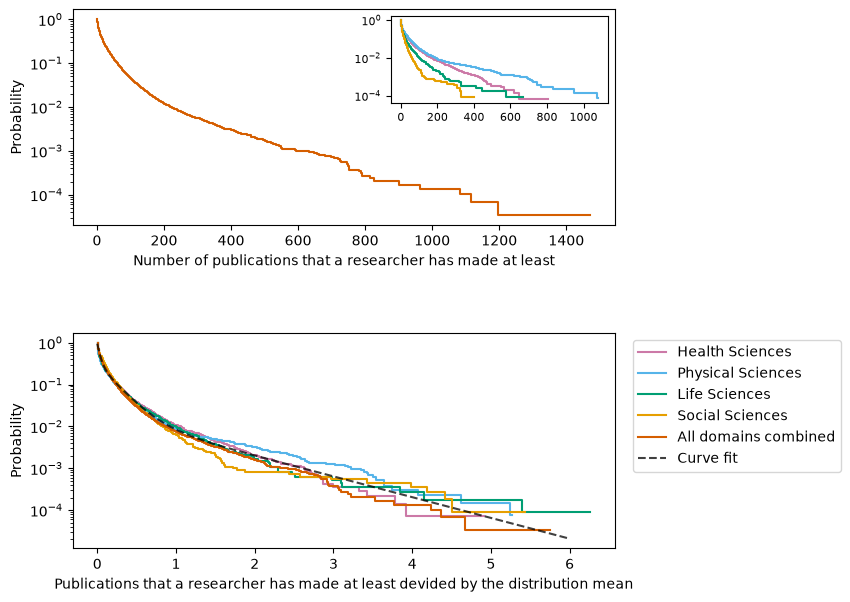

In [8]:
fig, ax = plt.subplots(nrows=2,ncols=1,figsize=(7, 7))
plt.subplots_adjust(hspace=0.5)
#figsize=(7, 4)
#cmap = plt.get_cmap('viridis')
#colors = cmap(np.linspace(0.1, 0.9, 4))
colors = ['#CC79A7', '#56B4E9', '#009E73','#E69F00']
fields_labels = ['Health Sciences','Physical Sciences','Life Sciences','Social Sciences']
ax[0].step(dif_all["value"],
           dif_all["surv_ge"],
           label = 'All domains combined',
           color='#D55E00')
# Inset plot
axins = inset_axes(
    ax[0],
    width="40%",
    height="40%",
    loc="upper right"
)

for i in range(0, 4):
    axins.step(
        difs[i][0],
        difs[i][1],
        label=fields_labels[i],
        color=colors[i]
    )

#axins.set_xlabel("Number of publications", fontsize=8)
#axins.set_ylabel("Probability", fontsize=8)
#axins.set_title("DIF plot (1 - CDF)", fontsize=9)
axins.set_yscale("log")
axins.tick_params(axis='both', labelsize=8)

#axins.legend(fontsize=7)
#for i in range(0,4):
 #   ax[0].step(difs[i][0], difs[i][1],label = fields_labels[i],color=colors[i])
ax[0].set_xlabel("Number of publications that a researcher has made at least")
ax[0].set_ylabel("Probability")
#ax[0].set_title("CCDF")
#ax[0].set_xscale("log")
ax[0].set_yscale("log")

alpha = 1.
alpha_fit = 0.75
for i in range(0,4):
    ax[1].step(difs_norm[i][0], difs_norm[i][1],label = fields_labels[i],alpha = alpha,color=colors[i])
ax[1].step(dif_norm_all[0], dif_norm_all[1],label = 'All domains combined',alpha = alpha,color='#D55E00')
ax[1].plot(x_fit,y_fit,linestyle = '--',color = (0,0,0),alpha=alpha_fit,label = 'Curve fit')
ax[1].set_xlabel("Publications that a researcher has made at least devided by the distribution mean")
ax[1].set_ylabel("Probability")
#ax[1].set_title("DIF plot rescaled")
#ax[1].set_xlim(right=10)
#ax[1].set_ylim(bottom=10**(-3))
#ax[1].set_xscale("log")
ax[1].set_yscale("log")
ax[1].legend(loc="upper left", bbox_to_anchor=(1.02, 1))
#plt.tight_layout()
path = Path('../plots/albert/CCDF_per_domain.png')
plt.savefig(path, dpi=300, bbox_inches='tight')
plt.show()

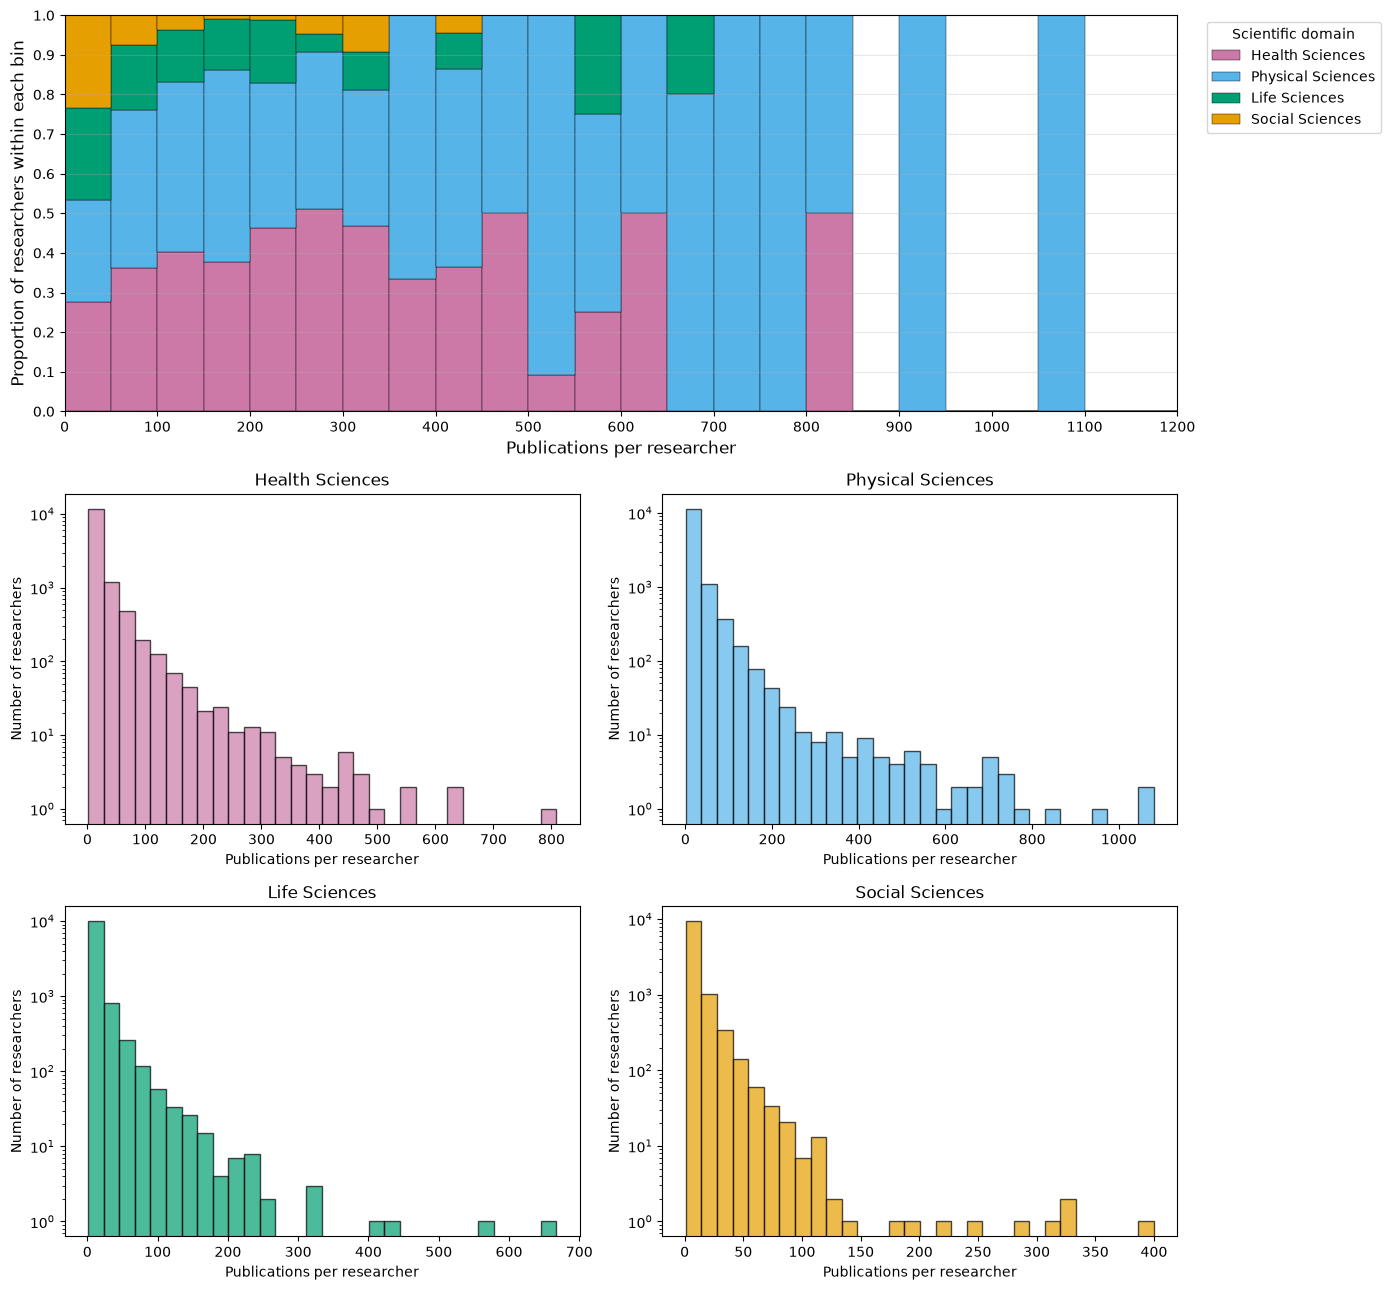

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# =====================================================
# Create figure layout: 3 rows x 2 columns
# =====================================================

fig = plt.figure(figsize=(14, 13))
gs = fig.add_gridspec(3, 2, height_ratios=[1.2, 1, 1])

# First plot spans both columns of the first row
ax0 = fig.add_subplot(gs[0, :])

# Four histograms in the remaining positions
axes = [
    fig.add_subplot(gs[1, 0]),
    fig.add_subplot(gs[1, 1]),
    fig.add_subplot(gs[2, 0]),
    fig.add_subplot(gs[2, 1])
]

# =====================================================
# 1. 100% stacked bar chart (first row)
# =====================================================

bins = np.arange(0, 1201, 50)

data = [grouped[i].values for i in range(4)]

histograms = []

for i in range(4):
    counts, _ = np.histogram(data[i], bins=bins)
    histograms.append(counts)

histograms = np.array(histograms)

# Calculate proportions within each bin
total_per_bin = histograms.sum(axis=0)

proportions = np.divide(
    histograms,
    total_per_bin,
    out=np.zeros_like(histograms, dtype=float),
    where=total_per_bin != 0
)

bin_centers = (bins[:-1] + bins[1:]) / 2
bin_width = bins[1] - bins[0]

bottom = np.zeros(len(bin_centers))

for i in range(4):
    ax0.bar(
        bin_centers,
        proportions[i],
        width=bin_width,
        bottom=bottom,
        label=fields_labels[i],
        edgecolor='black',
        color=colors[i],
        linewidth=0.3
    )

    bottom += proportions[i]

ax0.set_xlabel('Publications per researcher', fontsize=12)
ax0.set_ylabel('Proportion of researchers within each bin', fontsize=12)

#ax0.set_title(
 #   'Proportion of scientific domains across researcher-count bins',
  #  fontsize=14
#)

ax0.set_xlim(0, 1200)
ax0.set_ylim(0, 1)

ax0.set_xticks(np.arange(0, 1201, 100))
ax0.set_yticks(np.arange(0, 1.1, 0.1))

ax0.legend(title='Scientific domain',loc="upper left", bbox_to_anchor=(1.02, 1))
ax0.grid(axis='y', alpha=0.3)


# =====================================================
# 2. Four individual histograms (bottom two rows)
# =====================================================

for i, ax in enumerate(axes):

    ax.hist(
        grouped[i],
        bins=30,
        edgecolor='black',
        color=colors[i],
        alpha=0.7
    )

    ax.set_title(fields_labels[i])
    ax.set_yscale('log')

    ax.set_xlabel('Publications per researcher')
    ax.set_ylabel('Number of researchers')

    # ax.set_xlim(left=0, right=1200)
    # ax.set_xscale('log')
    # ax.grid(alpha=0.3)


# =====================================================
# Final layout
# =====================================================

fig.tight_layout()
path = Path('../plots/albert/Distribution_hist.png')
plt.savefig(path, dpi=300, bbox_inches='tight')
plt.show()